<a href="https://colab.research.google.com/github/pabloisai2199-ia/REDES-NEURONALES-ARTIFICIALES/blob/main/22_opt_momentum_PABLO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Optimizador momentum

(Ejercicio, 2 puntos posibles)

El optimizador de descenso por gradiente con momento es una variante del descenso por gradiente tradicional que ayuda a acelerar el entrenamiento de modelos, especialmente en superficies de error que son muy poco profundas o con curvaturas irregulares. La idea es tomar en cuenta los gradientes anteriores para determinar la dirección de la actualización en cada paso, lo que permite al método "acumular velocidad" en direcciones consistentes y suavizar las actualizaciones en direcciones variables.

En este ejercicio hay dos tareas:

1. **(1 punto)** Implementar el descenso por gradiente con momento.
2. **(1 punto)** Configurar `learning_rate`, `beta` y `max_iterations` para acercarte al óptimo de Beale $(3, 0.5)$ por debajo del umbral. Puedes usar hasta 2000 iteraciones.

El problema de Beale, la visualización y el ciclo `optimize` ya están dados.

INSTRUCCIONES: Completa el código faltante.



@juan1rving


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.animation as animation
import nni


In [ ]:
# --- Criterio de evaluación (fijo: no lo modifiques) ---
# Pesos iniciales
w_inicial = [-1.5, 3.0]
# Distancia euclidiana máxima al óptimo (3, 0.5)
umbral = 0.1
# Tope de iteraciones para la evaluación
max_iteraciones_permitidas = 2000


## Problema

La función de Beale es una conocida función de prueba en optimización matemática utilizada para evaluar y comparar el rendimiento de algoritmos de optimización. Esta función se usa comúnmente en pruebas de algoritmos debido a sus múltiples mínimos locales y un mínimo global, lo que la hace un desafío interesante para los algoritmos de optimización. Los parámetros que actualizamos son los pesos $w = (w_1, w_2)$.

$$
f(w_1, w_2) = (1.5 - w_1 + w_1 w_2)^2 + (2.25 - w_1 + w_1 w_2^2)^2 + (2.625 - w_1 + w_1 w_2^3)^2
$$

Características de la función de Beale:
- Mínimo global: La función tiene un mínimo global en $w = (3, 0.5)$ con un valor de $f(w)=0$.
- Mínimos locales: La función tiene varios mínimos locales, lo que la convierte en un desafío para los algoritmos de optimización que buscan el mínimo global.
- Superficie compleja: La superficie de la función es bastante compleja, lo que permite evaluar la capacidad de los algoritmos de optimización.


In [ ]:
problem = nni.ReducedBealeProblem()

def square_view(xs, ys, margin=0.20):
    x_min, x_max = min(xs), max(xs)
    y_min, y_max = min(ys), max(ys)
    dx = x_max - x_min
    dy = y_max - y_min
    span = max(dx, dy, 1e-6)
    pad_x = margin * (dx if dx > 0 else span)
    pad_y = margin * (dy if dy > 0 else span)
    x_min, x_max = x_min - pad_x, x_max + pad_x
    y_min, y_max = y_min - pad_y, y_max + pad_y
    side = max(x_max - x_min, y_max - y_min)
    cx = 0.5 * (x_min + x_max)
    cy = 0.5 * (y_min + y_max)
    half = side / 2.0
    return cx - half, cx + half, cy - half, cy + half

min_w1, max_w1, min_w2, max_w2 = square_view(
    [w_inicial[0], problem.optimal_params[0]],
    [w_inicial[1], problem.optimal_params[1]],
)

w1 = np.linspace(min_w1, max_w1, 200)
w2 = np.linspace(min_w2, max_w2, 200)
W1, W2 = np.meshgrid(w1, w2)
Z = problem.function(W1, W2)
Z_log = np.log(Z + 1)


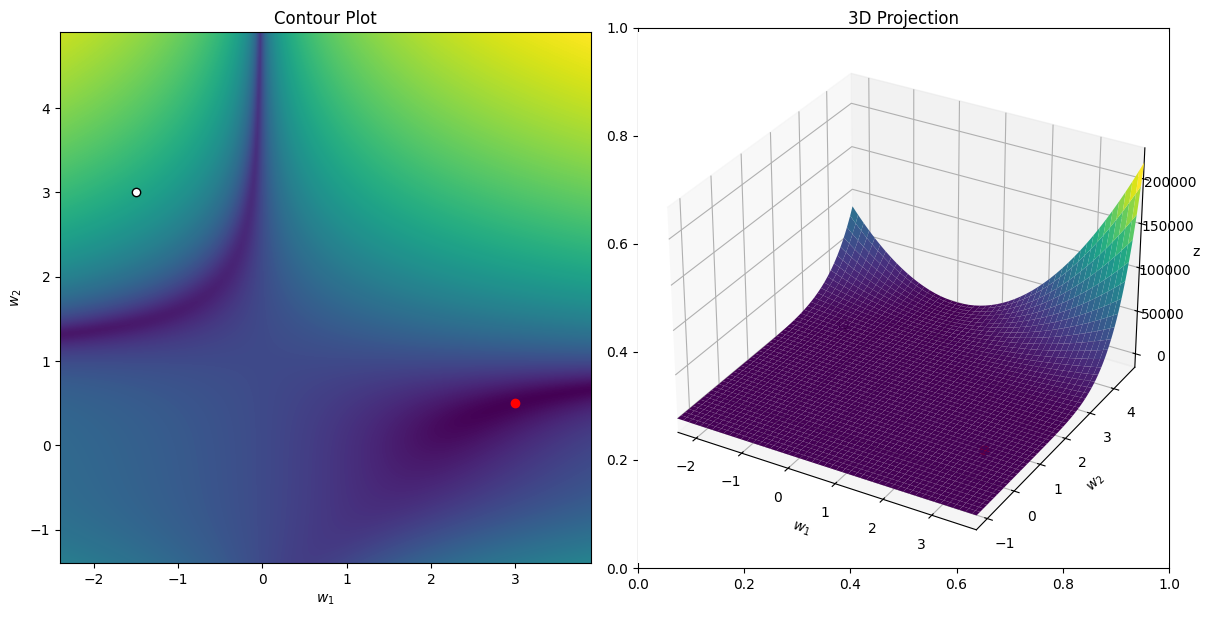

In [ ]:
# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.contourf(W1, W2, Z_log, levels=1000, cmap='viridis')
ax1.plot(w_inicial[0], w_inicial[1], 'wo', markeredgecolor='k')
ax1.plot(problem.optimal_params[0], problem.optimal_params[1], 'ro')
ax1.set_xlim(min_w1, max_w1)
ax1.set_ylim(min_w2, max_w2)
ax1.set_aspect('equal', adjustable='box')
ax1.set_xlabel(r'$w_1$')
ax1.set_ylabel(r'$w_2$')
ax1.set_title('Contour Plot')

ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(W1, W2, Z, cmap='viridis')
ax2.scatter(w_inicial[0], w_inicial[1], problem.function(*w_inicial),
            c='w', s=40, edgecolors='k')
ax2.scatter(problem.optimal_params[0], problem.optimal_params[1], 0, c='r', s=40)
ax2.set_xlim(min_w1, max_w1)
ax2.set_ylim(min_w2, max_w2)
ax2.set_xlabel(r'$w_1$')
ax2.set_ylabel(r'$w_2$')
ax2.set_zlabel('z')
ax2.set_title('3D Projection')

plt.tight_layout()
plt.show()


## Actualización con momento

El descenso por gradiente sin momento actualiza los pesos $w$ solo con el gradiente actual:

$$
w_{t} = w_{t-1} - \eta \nabla f(w_{t-1})
$$

Con momento se guarda un vector $v$ que combina el momento anterior con el gradiente actual. Usaremos el promedio exponencial:

$$
v_{t} = \beta v_{t-1} + (1-\beta)\nabla f(w_{t-1})
$$

$$
w_{t} = w_{t-1} - \eta v_{t}
$$

donde $\beta$ (beta) controla cuánta historia se conserva. Un valor típico es $\beta = 0.9$.

La clase `nni.GradientDescentOptimizer` ya implementa el ciclo `optimize`. Tú debes completar `MomentumOptimizer`: inicializar el vector de momento y sobrescribir `next_params`.


In [ ]:
class MomentumOptimizer(nni.GradientDescentOptimizer):
    def __init__(self, learning_rate=0.01, max_iterations=1000, tolerance=1e-6, beta=0.9):
        super().__init__(learning_rate=learning_rate, max_iterations=max_iterations, tolerance=tolerance)
        self.beta = beta
        self.name = 'Momentum'
        # TODO (1 punto): implementa el descenso por gradiente con momento.
        # Inicializa el vector de momento (misma dimensión que w: w1, w2).
        self.momentum = None

    def next_params(self, gradient, w):
        # Completa la actualización:
        # 1) Combina el momento anterior con el gradiente actual usando beta.
        # 2) Da el paso restando learning_rate * momento (no el gradiente crudo).
        gradient = np.array(gradient)
        w = np.array(w)

        if self.momentum is None:
            self.momentum = np.zeros_like(w)

        self.momentum = self.beta * self.momentum + (1 - self.beta) * gradient

        new_w = w - self.learning_rate * self.momentum

        return new_w


In [ ]:
# TODO (1 punto): configura learning_rate, beta y max_iterations
# para acercarte al óptimo. Se considera que llegaste si, en no más
# de 2000 pasos, la distancia a (3, 0.5) es menor que umbral.
learning_rate = 0.0025
beta = 0.9
max_iterations = 2000


In [ ]:
max_iterations_run = min(int(max_iterations), max_iteraciones_permitidas)
if max_iterations > max_iteraciones_permitidas:
    print(f'Aviso: max_iterations se recortó a {max_iteraciones_permitidas}.')

optimizer = MomentumOptimizer(
    learning_rate=learning_rate,
    max_iterations=max_iterations_run,
    tolerance=1e-6,
    beta=beta,
)

w = optimizer.optimize(
    problem.function,
    lambda w1, w2: [problem.gradient_x(w1, w2), problem.gradient_y(w1, w2)],
    w_inicial,
)

history = optimizer.get_history()
k = min(len(history), max_iteraciones_permitidas)
w_eval = np.array(history[k - 1]['params'], dtype=float)
w_optimo = np.array(problem.optimal_params, dtype=float)
distancia = np.linalg.norm(w_eval - w_optimo)
llego = np.isfinite(distancia) and distancia < umbral

print(f'w evaluado: {w_eval}')
print(f'w óptimo: {w_optimo}')
print(f'Mejor valor encontrado: {problem.function(*w_eval)}')
print(f'Distancia al óptimo: {distancia:.4f}  (umbral = {umbral})')
print(f'Iteraciones: {k}  (máximo permitido = {max_iteraciones_permitidas})')
if llego:
    print('Evaluación: SÍ se acerca al óptimo.')
else:
    print('Evaluación: NO se acerca al óptimo. Ajusta learning_rate, beta y max_iterations.')


w evaluado: [2.90815994 0.47613524]
w óptimo: [3.  0.5]
Mejor valor encontrado: 0.0014984627241529688
Distancia al óptimo: 0.0949  (umbral = 0.1)
Iteraciones: 2000  (máximo permitido = 2000)
Evaluación: SÍ se acerca al óptimo.


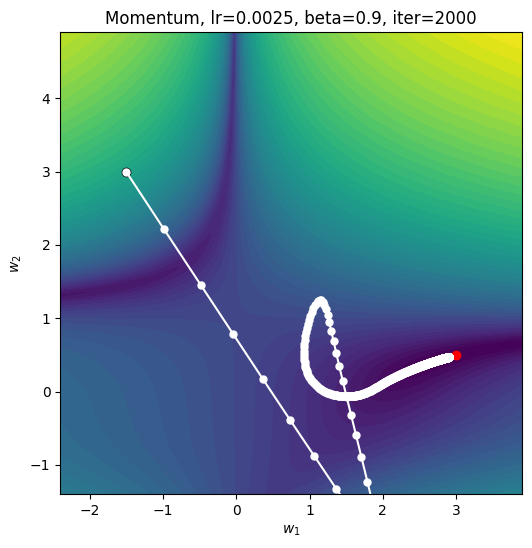

In [ ]:
history = optimizer.get_history()
w1_values = [log['params'][0] for log in history]
w2_values = [log['params'][1] for log in history]

min_w1, max_w1, min_w2, max_w2 = square_view(
    [w1_values[0], problem.optimal_params[0]],
    [w2_values[0], problem.optimal_params[1]],
)
w1 = np.linspace(min_w1, max_w1, 200)
w2 = np.linspace(min_w2, max_w2, 200)
W1, W2 = np.meshgrid(w1, w2)
Z_log = np.log(problem.function(W1, W2) + 1)

fig, ax = plt.subplots(figsize=(6, 6))
ax.contourf(W1, W2, Z_log, levels=50, cmap='viridis')
ax.plot(w1_values[0], w2_values[0], 'wo', markeredgecolor='k')
ax.plot(problem.optimal_params[0], problem.optimal_params[1], 'ro')
ax.plot(w1_values, w2_values, 'w.-', markersize=10)
ax.set_xlim(min_w1, max_w1)
ax.set_ylim(min_w2, max_w2)
ax.set_aspect('equal', adjustable='box')
ax.set_xlabel(r'$w_1$')
ax.set_ylabel(r'$w_2$')
ax.set_title(f'{optimizer.name}, lr={optimizer.learning_rate}, beta={optimizer.beta}, iter={len(history)}')
plt.show()


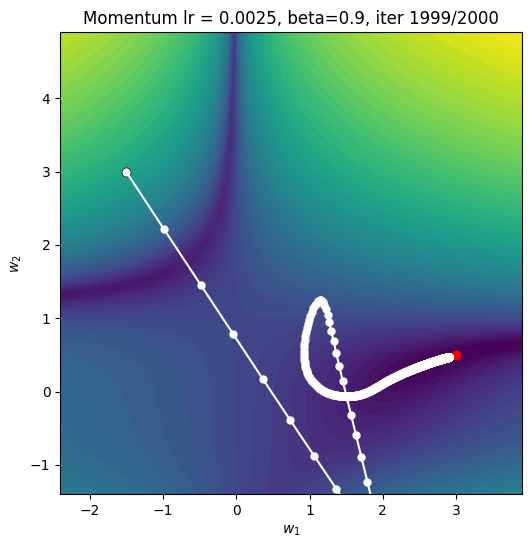

In [ ]:
#Animate and save the optimization process
fig, ax = plt.subplots(figsize=(6, 6))
ax.contourf(W1, W2, Z_log, levels=50, cmap='viridis')
ax.plot(w1_values[0], w2_values[0], 'wo', markeredgecolor='k')
ax.plot(problem.optimal_params[0], problem.optimal_params[1], 'ro')
(line,) = ax.plot([], [], 'w.-', markersize=10)
ax.set_xlim(min_w1, max_w1)
ax.set_ylim(min_w2, max_w2)
ax.set_aspect('equal', adjustable='box')
ax.set_xlabel(r'$w_1$')
ax.set_ylabel(r'$w_2$')
title = ax.set_title('')

def update(frame):
    line.set_data(w1_values[:frame + 1], w2_values[:frame + 1])
    title.set_text(f'{optimizer.name} lr = {optimizer.learning_rate}, beta={optimizer.beta}, iter {frame}/{len(w1_values)}')
    return (line, title)

animation.FuncAnimation(fig, update, frames=len(w1_values), interval=30, blit=True, repeat=False).save('momentum_beta.mp4')
